# Postpartum Anxiety-Symptom Screening: A Leakage-Aware Comparison of Machine-Learning Models

Data: Kaggle *PostPartum Depression* survey. Task: predict the self-reported item **Feeling anxious** from the other symptom items and age band.
This is symptom screening, not a diagnosis and not early prediction.

**Sections:** 1 Setup · 2 Load · 3 Data quality · 4 Prepare · 5 Split · 6 Models · 7 Cross-validation · 8 Statistical comparison · 9 Select and tune · 10 Explanation stability · 11 Fewer questions · 12 Label noise · 13 Age groups · 14 Final test · 15 Calibration, tiers, decision curve · 16 Important questions · 17 Leakage check · 18 Summary

## 1. Setup

In [1]:
import warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import shap
from scipy import stats
from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, balanced_accuracy_score,
                             matthews_corrcoef, confusion_matrix, RocCurveDisplay)
from sklearn.model_selection import (StratifiedGroupKFold, StratifiedKFold, RandomizedSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.naive_bayes import BernoulliNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
N_SPLITS, N_REPEATS = 5, 3      # repeated cross-validation on the training data
GAP_LIMIT = 0.10                # models with train-minus-validation AUC above this are treated as overfitted
DATA_FILE = "post natal data.csv"
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

## 2. Load the data

In [2]:
raw = pd.read_csv(DATA_FILE)
print(raw.shape)
raw.head(3)

(1503, 11)


,Timestamp,Age,Feeling sad or Tearful,Irritable towards baby & partner,Trouble sleeping at night,Problems concentrating or making decision,Overeating or loss of appetite,Feeling anxious,Feeling of guilt,Problems of bonding with baby,Suicide attempt
0,6/14/2022 20:02,35-40,Yes,Yes,Two or more days a week,Yes,Yes,Yes,No,Yes,Yes
1,6/14/2022 20:03,40-45,Yes,No,No,Yes,Yes,No,Yes,Yes,No
2,6/14/2022 20:04,35-40,Yes,No,Yes,Yes,Yes,Yes,No,Sometimes,No


## 3. Check data quality
Repeated answer patterns matter: if identical rows land in both training and test data, a model can look accurate by memorising them.

In [3]:
TARGET = "Feeling anxious"
FEATURES = [c for c in raw.columns if c not in ("Timestamp", TARGET)]

X_raw = raw[FEATURES].astype(object)
y_raw = (raw[TARGET] == "Yes").astype(int).to_numpy()

pattern = X_raw.fillna("<missing>").astype(str).agg("|".join, axis=1)
pattern_id = pd.factorize(pattern)[0]
is_repeat = pd.Series(pattern + "|" + pd.Series(y_raw).astype(str)).duplicated().to_numpy()
by_pattern = pd.DataFrame({"p": pattern_id, "y": y_raw}).groupby("p")["y"].agg(["mean", "count"])

print(f"Rows: {len(raw)} | missing cells: {int(X_raw.isna().sum().sum())}")
print(f"Distinct timestamps: {raw['Timestamp'].nunique()} (up to {raw['Timestamp'].value_counts().max()} rows share one)")
print(f"Distinct answer patterns: {(~is_repeat).sum()} -> {is_repeat.sum()} rows ({is_repeat.mean():.0%}) repeat an earlier row")
print(f"Patterns seen with both labels: {int(by_pattern['mean'].between(0, 1, inclusive='neither').sum())}")
print(f"Anxious = Yes: raw {y_raw.mean():.1%} | repeats removed {y_raw[~is_repeat].mean():.1%}")

Rows: 1503 | missing cells: 27
Distinct timestamps: 90 (up to 51 rows share one)
Distinct answer patterns: 326 -> 1177 rows (78%) repeat an earlier row
Patterns seen with both labels: 0
Anxious = Yes: raw 65.2% | repeats removed 58.0%


## 4. Prepare the analysis data
Each distinct response is kept once. Filling gaps and one-hot encoding happen inside the model pipeline, so they learn from training data only.

In [4]:
keep = ~is_repeat
X = X_raw[keep].reset_index(drop=True)
y = y_raw[keep]
groups = pattern_id[keep]

def make_preprocessor():
    return Pipeline([("fill", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

print(f"{len(y)} responses | {y.sum()} anxious ({y.mean():.1%}) | {len(set(groups))} answer patterns")

326 responses | 189 anxious (58.0%) | 326 answer patterns


## 5. Hold out a test set
20% is locked away and used once, in Step 14. Splits are stratified by label and grouped by answer pattern.

In [5]:
train_idx, test_idx = next(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(X, y, groups))
X_train, y_train, g_train = X.iloc[train_idx], y[train_idx], groups[train_idx]
X_test,  y_test,  g_test  = X.iloc[test_idx],  y[test_idx],  groups[test_idx]
print(f"Train {len(y_train)} ({y_train.mean():.1%} anxious) | Test {len(y_test)} ({y_test.mean():.1%} anxious) | shared patterns: {len(set(g_train) & set(g_test))}")

Train 260 (58.1% anxious) | Test 66 (57.6% anxious) | shared patterns: 0


## 6. Candidate models
The data are nine coarse categorical questions and about 260 training rows, so simple regularised models are expected to compete well. Flexible models and ensembles are included to test whether they add anything.

| Model | Why it is included |
|---|---|
| Dummy | Floor: any real model must beat it |
| Logistic regression | Standard for questionnaires, transparent, hard to overfit |
| Naive Bayes | Natural for yes/no items, very fast |
| Decision tree | Readable rules |
| SVM (RBF) | Common in the postpartum literature |
| Random forest | Captures interactions, robust on small data |
| Gradient boosting | Strong tabular learner, overfits easily |
| Voting / stacking | Test whether combining models helps |

Models are listed from simplest to most complex; Step 9 uses that order as a tie-breaker.

In [6]:
def pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("clf", model)])

def make_rf():  return RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=3, random_state=SEED)
def make_gb():  return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=100, min_samples_leaf=10,
                                                      l2_regularization=1.0, random_state=SEED)
def make_lr():  return LogisticRegression(C=1.0, max_iter=2000)
def members():  return [("lr", make_lr()), ("rf", make_rf()), ("gb", make_gb())]

MODELS = {
    "Dummy":                lambda: DummyClassifier(strategy="prior"),
    "Logistic regression":  lambda: pipe(make_lr()),
    "Naive Bayes":          lambda: pipe(BernoulliNB()),
    "Decision tree":        lambda: pipe(DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=SEED)),
    "SVM (RBF)":            lambda: pipe(SVC(C=1.0, probability=True, random_state=SEED)),
    "Random forest":        lambda: pipe(make_rf()),
    "Gradient boosting":    lambda: pipe(make_gb()),
    "Soft-voting ensemble": lambda: pipe(VotingClassifier(members(), voting="soft")),
    "Stacking ensemble":    lambda: pipe(StackingClassifier(members(), final_estimator=LogisticRegression(max_iter=2000),
                                                            cv=StratifiedKFold(5, shuffle=True, random_state=SEED))),
}
list(MODELS)

['Dummy',
 'Logistic regression',
 'Naive Bayes',
 'Decision tree',
 'SVM (RBF)',
 'Random forest',
 'Gradient boosting',
 'Soft-voting ensemble',
 'Stacking ensemble']

## 7. Compare models with repeated cross-validation (training data only)
Every model is trained and validated on 15 different splits. A large gap between train and validation AUC signals overfitting.

In [7]:
def repeated_group_folds(y_, groups_, n_splits=N_SPLITS, n_repeats=N_REPEATS):
    folds = []
    for r in range(n_repeats):
        folds += list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=SEED + r).split(np.zeros(len(y_)), y_, groups_))
    return folds

cv_folds = repeated_group_folds(y_train, g_train)
scoring = {"auc": "roc_auc", "brier": "neg_brier_score", "bal_acc": "balanced_accuracy"}

rows, fold_auc = [], {}
for name, make in MODELS.items():
    res = cross_validate(make(), X_train, y_train, cv=cv_folds, scoring=scoring, return_train_score=True)
    fold_auc[name] = res["test_auc"]
    rows.append({"Model": name, "Train AUC": res["train_auc"].mean(), "Validation AUC": res["test_auc"].mean(),
                 "SE": res["test_auc"].std(ddof=1) / np.sqrt(len(cv_folds)),
                 "Gap": res["train_auc"].mean() - res["test_auc"].mean(),
                 "Brier": -res["test_brier"].mean(), "Balanced acc.": res["test_bal_acc"].mean()})
cv_table = pd.DataFrame(rows).set_index("Model")
cv_table.to_csv(RESULTS / "cv_comparison.csv")
cv_table.round(3)

,Train AUC,Validation AUC,SE,Gap,Brier,Balanced acc.
Model,,,,,,
Dummy,0.500,0.500,0.000,0.000,0.244,0.500
Logistic regression,0.871,0.805,0.009,0.066,0.182,0.723
Naive Bayes,0.859,0.817,0.007,0.041,0.184,0.723
Decision tree,0.842,0.771,0.015,0.071,0.189,0.721
SVM (RBF),0.978,0.840,0.010,0.138,0.163,0.764
Random forest,0.938,0.842,0.009,0.097,0.170,0.758
Gradient boosting,0.952,0.825,0.011,0.128,0.170,0.748
Soft-voting ensemble,0.929,0.830,0.010,0.099,0.169,0.745
Stacking ensemble,0.937,0.832,0.010,0.104,0.171,0.746


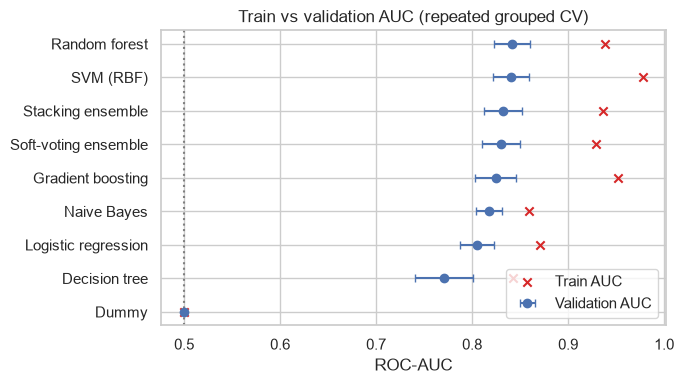

In [8]:
order = cv_table["Validation AUC"].sort_values().index
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(cv_table.loc[order, "Validation AUC"], range(len(order)), xerr=1.96 * cv_table.loc[order, "SE"], fmt="o", capsize=3, label="Validation AUC")
ax.scatter(cv_table.loc[order, "Train AUC"], range(len(order)), marker="x", color="tab:red", label="Train AUC")
ax.axvline(0.5, color="grey", ls=":"); ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set(xlabel="ROC-AUC", title="Train vs validation AUC (repeated grouped CV)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8. Are the differences real?
Paired per-fold AUC differences against logistic regression, tested with the Nadeau-Bengio corrected t-test (it allows for overlapping training sets) and Holm adjustment for multiple comparisons. Then: do the ensembles beat their best member, and do the members make different mistakes?

In [9]:
n_tr = np.mean([len(tr) for tr, _ in cv_folds]); n_te = np.mean([len(te) for _, te in cv_folds])

def corrected_t_test(diff):
    diff = np.asarray(diff, float); J = len(diff)
    if np.isclose(diff.std(ddof=1), 0): return 0.0, 1.0
    t = diff.mean() / np.sqrt((1 / J + n_te / n_tr) * diff.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), J - 1)

def holm_adjust(p):
    p = np.asarray(p, float); order = np.argsort(p); adj = np.empty(len(p)); running = 0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i]); adj[i] = min(1.0, running)
    return adj

REFERENCE = "Logistic regression"
rows = []
for name in MODELS:
    if name == REFERENCE: continue
    d = fold_auc[name] - fold_auc[REFERENCE]; t, p = corrected_t_test(d)
    rows.append({"Model": name, "AUC difference vs LR": d.mean(), "p": p})
vs_lr = pd.DataFrame(rows).set_index("Model"); vs_lr["p (Holm)"] = holm_adjust(vs_lr["p"])
vs_lr.round(4)

,AUC difference vs LR,p,p (Holm)
Model,,,
Dummy,-0.3049,0.0000,0.0000
Naive Bayes,0.0125,0.4064,0.6885
Decision tree,-0.0340,0.2295,0.6885
SVM (RBF),0.0353,0.0374,0.1869
Random forest,0.0366,0.0091,0.0640
Gradient boosting,0.0197,0.2628,0.6885
Soft-voting ensemble,0.0248,0.0282,0.1694
Stacking ensemble,0.0272,0.0420,0.1869


In [10]:
singles = ["Logistic regression", "Random forest", "Gradient boosting"]
best_member = max(singles, key=lambda m: fold_auc[m].mean())
for ens in ["Soft-voting ensemble", "Stacking ensemble"]:
    d = fold_auc[ens] - fold_auc[best_member]; t, p = corrected_t_test(d)
    print(f"{ens} minus {best_member}: AUC difference {d.mean():+.3f}, corrected-t p = {p:.3f}")

oof = {m: cross_val_predict(MODELS[m](), X_train, y_train, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
                            groups=g_train, method="predict_proba")[:, 1] for m in singles}
errors = pd.DataFrame({m: ((p >= 0.5).astype(int) != y_train).astype(int) for m, p in oof.items()})
print("\nError correlation between ensemble members (1 = always wrong together):")
errors.corr().round(2)

Soft-voting ensemble minus Random forest: AUC difference -0.012, corrected-t p = 0.075
Stacking ensemble minus Random forest: AUC difference -0.009, corrected-t p = 0.098

Error correlation between ensemble members (1 = always wrong together):


,Logistic regression,Random forest,Gradient boosting
Logistic regression,1.00,0.70,0.72
Random forest,0.70,1.00,0.71
Gradient boosting,0.72,0.71,1.00


## 9. Select the final model and tune it
Rule (training data only): (1) drop models whose train-minus-validation gap is above `GAP_LIMIT`; (2) keep those within one standard error of the best; (3) pick the simplest.
Tuning is kept only if nested cross-validation shows it beats the untuned model.

In [11]:
allowed = [m for m in MODELS if m != "Dummy" and cv_table.loc[m, "Gap"] <= GAP_LIMIT]
best = cv_table.loc[allowed, "Validation AUC"].idxmax()
cutoff = cv_table.loc[best, "Validation AUC"] - cv_table.loc[best, "SE"]
eligible = [m for m in allowed if cv_table.loc[m, "Validation AUC"] >= cutoff]
selected = eligible[0]
print("Dropped for overfitting:", [m for m in MODELS if m != "Dummy" and m not in allowed])
print(f"Best remaining: {best} | within 1 SE: {eligible} | selected: {selected}")

Dropped for overfitting: ['SVM (RBF)', 'Gradient boosting', 'Stacking ensemble']
Best remaining: Random forest | within 1 SE: ['Random forest'] | selected: Random forest


In [12]:
SPACES = {
    "Logistic regression": {"clf__C": loguniform(1e-3, 1e2)},
    "SVM (RBF)": {"clf__C": loguniform(0.1, 50), "clf__gamma": loguniform(1e-3, 1)},
    "Decision tree": {"clf__max_depth": [2, 3, 4, 5], "clf__min_samples_leaf": [5, 10, 20, 30]},
    "Random forest": {"clf__n_estimators": [200, 400], "clf__max_depth": [2, 3, 4, 6],
                      "clf__min_samples_leaf": [1, 3, 5, 10], "clf__max_features": ["sqrt", 0.5]},
    "Gradient boosting": {"clf__learning_rate": loguniform(0.01, 0.2), "clf__max_depth": [2, 3, 4],
                          "clf__max_iter": [50, 100, 200], "clf__min_samples_leaf": [5, 10, 20],
                          "clf__l2_regularization": loguniform(1e-3, 10)},
}
untuned_auc = cv_table.loc[selected, "Validation AUC"]
final_model, validation_auc = MODELS[selected]().fit(X_train, y_train), untuned_auc

if selected in SPACES:
    def new_search():
        return RandomizedSearchCV(MODELS[selected](), SPACES[selected], n_iter=20, scoring="neg_log_loss",
                                  cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED), random_state=SEED, refit=True)
    nested = [roc_auc_score(y_train[te], new_search().fit(X_train.iloc[tr], y_train[tr], groups=g_train[tr])
                            .predict_proba(X_train.iloc[te])[:, 1]) for tr, te in cv_folds]
    nested_auc = float(np.mean(nested))
    print(f"Validation AUC: untuned {untuned_auc:.3f} | tuned (nested CV) {nested_auc:.3f}")
    if nested_auc > untuned_auc:
        search = new_search().fit(X_train, y_train, groups=g_train)
        final_model, validation_auc = search.best_estimator_, nested_auc
        print("Tuning kept:", search.best_params_)
    else:
        print("Tuning rejected; default settings are used.")

Validation AUC: untuned 0.842 | tuned (nested CV) 0.853
Tuning kept: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 1, 'clf__max_features': 0.5, 'clf__max_depth': 6}


## 10. Do the explanations stay the same across folds?
SHAP values are computed on the validation part of each fold for the selected model, summed back to the original question, and ranked. High agreement between folds means the ranking can be trusted more.

Background dataset has 208 samples but max_samples=50. Subsampling to 50 samples for SHAP value computation. To use all samples, set max_samples=208 when initializing the masker.
Background dataset has 208 samples but max_samples=50. Subsampling to 50 samples for SHAP value computation. To use all samples, set max_samples=208 when initializing the masker.
Background dataset has 208 samples but max_samples=50. Subsampling to 50 samples for SHAP value computation. To use all samples, set max_samples=208 when initializing the masker.
Background dataset has 208 samples but max_samples=50. Subsampling to 50 samples for SHAP value computation. To use all samples, set max_samples=208 when initializing the masker.
Background dataset has 208 samples but max_samples=50. Subsampling to 50 samples for SHAP value computation. To use all samples, set max_samples=208 when initializing the masker.
Background dataset has 208 samples but max_samples=50. Subsampling to 50 samples for SHAP value computati

Median Kendall tau between folds: 0.67 | median top-3 overlap (Jaccard): 0.50
Most important question in 100% of folds: Feeling of guilt


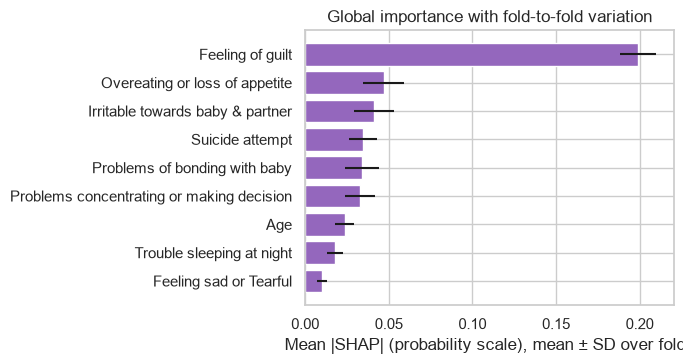

In [13]:
def item_columns(fitted_prep):
    cats = fitted_prep.named_steps["onehot"].categories_; out, start = [], 0
    for c in cats: out.append(np.arange(start, start + len(c))); start += len(c)
    return out

shap_by_fold = []
for tr, te in cv_folds[:10]:
    m = clone(final_model).fit(X_train.iloc[tr], y_train[tr])
    A, B = m.named_steps["prep"].transform(X_train.iloc[tr]), m.named_steps["prep"].transform(X_train.iloc[te])
    f = lambda Z, clf=m.named_steps["clf"]: clf.predict_proba(Z)[:, 1]
    values = shap.Explainer(f, shap.maskers.Independent(A, max_samples=50))(B, silent=True).values
    shap_by_fold.append([np.abs(values[:, cols].sum(axis=1)).mean() for cols in item_columns(m.named_steps["prep"])])
shap_df = pd.DataFrame(shap_by_fold, columns=X_train.columns)

taus = [stats.kendalltau(shap_df.iloc[i], shap_df.iloc[j])[0] for i in range(len(shap_df)) for j in range(i + 1, len(shap_df))]
top3 = [set(r.nlargest(3).index) for _, r in shap_df.iterrows()]
jaccard = [len(top3[i] & top3[j]) / len(top3[i] | top3[j]) for i in range(len(top3)) for j in range(i + 1, len(top3))]
print(f"Median Kendall tau between folds: {np.median(taus):.2f} | median top-3 overlap (Jaccard): {np.median(jaccard):.2f}")
print("Most important question in", f"{(shap_df.idxmax(axis=1) == shap_df.mean().idxmax()).mean():.0%}", "of folds:", shap_df.mean().idxmax())

fig, ax = plt.subplots(figsize=(7, 3.8))
order = shap_df.mean().sort_values().index
ax.barh(order, shap_df.mean()[order], xerr=shap_df.std()[order], color="tab:purple")
ax.set(xlabel="Mean |SHAP| (probability scale), mean ± SD over folds", title="Global importance with fold-to-fold variation")
plt.tight_layout(); plt.show()

## 11. How few questions are enough?
Questions are ranked by mutual information with the label **inside each training fold**, and the model is refitted using only the top k.

Smallest number of questions within 1 SE of using all 9: 7


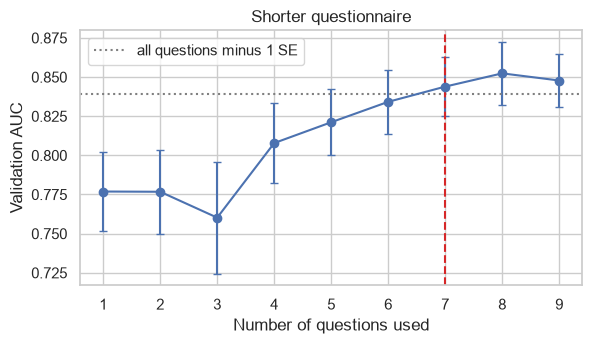

Questions,1,2,3,4,5,6,7,8,9
AUC,0.777,0.777,0.760,0.808,0.821,0.834,0.844,0.852,0.848
SE,0.013,0.014,0.018,0.013,0.011,0.010,0.010,0.010,0.009


In [14]:
def top_k_questions(Xtr, ytr, k):
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    A = enc.fit_transform(Xtr.fillna("<missing>").astype(str))
    mi = mutual_info_classif(A, ytr, discrete_features=True, random_state=SEED)
    return list(Xtr.columns[np.argsort(mi)[::-1][:k]])

k_values, rows = range(1, X_train.shape[1] + 1), []
for k in k_values:
    scores = []
    for tr, te in cv_folds:
        cols = top_k_questions(X_train.iloc[tr], y_train[tr], k)
        m = clone(final_model).fit(X_train.iloc[tr][cols], y_train[tr])
        scores.append(roc_auc_score(y_train[te], m.predict_proba(X_train.iloc[te][cols])[:, 1]))
    rows.append({"Questions": k, "AUC": np.mean(scores), "SE": np.std(scores, ddof=1) / np.sqrt(len(scores))})
screener = pd.DataFrame(rows).set_index("Questions")
full = screener.loc[X_train.shape[1]]
smallest = int(screener[screener["AUC"] >= full["AUC"] - full["SE"]].index.min())
print(f"Smallest number of questions within 1 SE of using all {X_train.shape[1]}: {smallest}")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(screener.index, screener["AUC"], yerr=1.96 * screener["SE"], marker="o", capsize=3)
ax.axhline(full["AUC"] - full["SE"], color="grey", ls=":", label="all questions minus 1 SE"); ax.axvline(smallest, color="tab:red", ls="--")
ax.set(xlabel="Number of questions used", ylabel="Validation AUC", title="Shorter questionnaire"); ax.legend()
plt.tight_layout(); plt.show()
screener.round(3).T

## 12. Robustness to label noise
A fraction of training labels is flipped at random; the models are scored on clean validation labels. A flatter line means a more robust model.

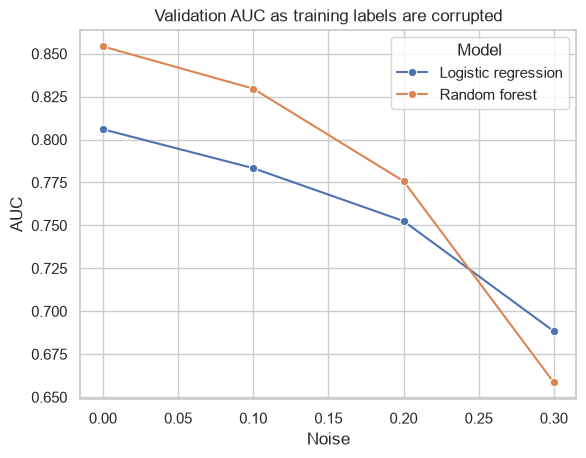

Model,Logistic regression,Random forest
Noise,,
0.0,0.806,0.854
0.1,0.783,0.830
0.2,0.753,0.776
0.3,0.688,0.659


In [15]:
rng = np.random.default_rng(SEED)
noise_levels, rows = [0.0, 0.1, 0.2, 0.3], []
for noise in noise_levels:
    for name, make in [("Logistic regression", MODELS["Logistic regression"]), (selected, lambda: clone(final_model))]:
        scores = []
        for tr, te in cv_folds[:10]:
            y_noisy = y_train[tr].copy(); flip = rng.random(len(tr)) < noise; y_noisy[flip] = 1 - y_noisy[flip]
            m = make().fit(X_train.iloc[tr], y_noisy)
            scores.append(roc_auc_score(y_train[te], m.predict_proba(X_train.iloc[te])[:, 1]))
        rows.append({"Noise": noise, "Model": name, "AUC": np.mean(scores)})
noise_df = pd.DataFrame(rows)
sns.lineplot(data=noise_df, x="Noise", y="AUC", hue="Model", marker="o"); plt.title("Validation AUC as training labels are corrupted"); plt.show()
noise_df.pivot(index="Noise", columns="Model", values="AUC").round(3)

## 13. Results by age group (training data, out-of-fold)
Exploratory only: each group is small.

In [16]:
p_oof = cross_val_predict(clone(final_model), X_train, y_train, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
                          groups=g_train, method="predict_proba")[:, 1]
rng = np.random.default_rng(SEED); rows = []
for band, idx in X_train.groupby("Age").indices.items():
    yy, pp = y_train[idx], p_oof[idx]
    if len(np.unique(yy)) == 2:
        boots = [roc_auc_score(yy[b], pp[b]) for b in (rng.integers(0, len(idx), len(idx)) for _ in range(500)) if len(np.unique(yy[b])) == 2]
        auc, lo, hi = roc_auc_score(yy, pp), *np.percentile(boots, [2.5, 97.5])
    else:
        auc = lo = hi = np.nan
    rows.append({"Age": band, "n": len(idx), "Anxious": f"{yy.mean():.0%}", "AUC (95% CI)": f"{auc:.2f} [{lo:.2f}, {hi:.2f}]"})
pd.DataFrame(rows).set_index("Age")

,n,Anxious,AUC (95% CI)
Age,,,
25-30,38,47%,"0.64 [0.45, 0.81]"
30-35,60,57%,"0.93 [0.85, 0.98]"
35-40,64,59%,"0.88 [0.77, 0.96]"
40-45,55,56%,"0.82 [0.70, 0.93]"
45-50,43,70%,"0.84 [0.72, 0.94]"


## 14. Final evaluation on the held-out test set
The test set is used here for the first time, with the model chosen above.

In [17]:
def score_all(model, X_, y_, threshold=0.5):
    p = model.predict_proba(X_)[:, 1]; pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
    return dict(AUC=roc_auc_score(y_, p), PR_AUC=average_precision_score(y_, p), Brier=brier_score_loss(y_, p),
                Accuracy=(tp + tn) / len(y_), Balanced_acc=balanced_accuracy_score(y_, pred),
                Sensitivity=tp / (tp + fn), Specificity=tn / (tn + fp), MCC=matthews_corrcoef(y_, pred)), p

def bootstrap_ci(model, X_, y_, g_, n_boot=1000):
    rng = np.random.default_rng(SEED); ug = np.unique(g_); where = {g: np.where(g_ == g)[0] for g in ug}
    p = model.predict_proba(X_)[:, 1]; out = []
    for _ in range(n_boot):
        idx = np.concatenate([where[g] for g in rng.choice(ug, len(ug))])
        if len(np.unique(y_[idx])) == 2:
            out.append([roc_auc_score(y_[idx], p[idx]), brier_score_loss(y_[idx], p[idx]), balanced_accuracy_score(y_[idx], p[idx] >= 0.5)])
    return np.percentile(np.array(out), [2.5, 97.5], axis=0).T

dummy = MODELS["Dummy"]().fit(X_train, y_train)
train_scores, _ = score_all(final_model, X_train, y_train)
test_scores, p_test = score_all(final_model, X_test, y_test)
dummy_scores, _ = score_all(dummy, X_test, y_test)
ci = bootstrap_ci(final_model, X_test, y_test, g_test)

summary = pd.DataFrame({f"{selected} (train)": train_scores, f"{selected} (test)": test_scores, "Dummy (test)": dummy_scores}).T
summary.to_csv(RESULTS / "final_scores.csv")
print(f"Test AUC 95% CI [{ci[0,0]:.3f}, {ci[0,1]:.3f}] | Brier [{ci[1,0]:.3f}, {ci[1,1]:.3f}] | Balanced acc. [{ci[2,0]:.3f}, {ci[2,1]:.3f}]")
summary.round(3)

Test AUC 95% CI [0.645, 0.874] | Brier [0.140, 0.264] | Balanced acc. [0.600, 0.822]


,AUC,PR_AUC,Brier,Accuracy,Balanced_acc,Sensitivity,Specificity,MCC
Random forest (train),0.997,0.998,0.054,0.954,0.946,0.993,0.899,0.907
Random forest (test),0.768,0.845,0.197,0.727,0.721,0.763,0.679,0.442
Dummy (test),0.500,0.576,0.244,0.576,0.500,1.000,0.000,0.000


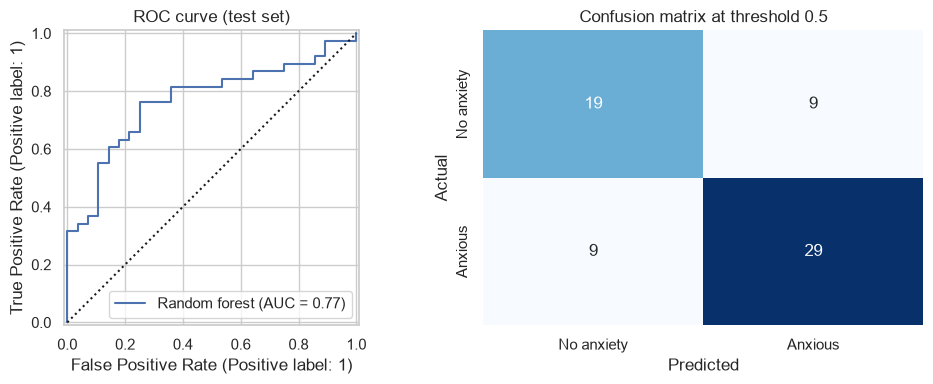

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[0], name=selected); ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("ROC curve (test set)")
sns.heatmap(confusion_matrix(y_test, (p_test >= 0.5).astype(int)), annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[1],
            xticklabels=["No anxiety", "Anxious"], yticklabels=["No anxiety", "Anxious"])
ax[1].set(xlabel="Predicted", ylabel="Actual", title="Confusion matrix at threshold 0.5"); plt.tight_layout(); plt.show()

In [19]:
# For reference only (nothing was chosen from this table): every candidate on the test set
ref = []
for name, make in MODELS.items():
    s, _ = score_all(make().fit(X_train, y_train), X_test, y_test)
    ref.append({"Model": name, "Test AUC": s["AUC"], "Validation AUC (Step 7)": cv_table.loc[name, "Validation AUC"]})
pd.DataFrame(ref).set_index("Model").round(3)

,Test AUC,Validation AUC (Step 7)
Model,,
Dummy,0.500,0.500
Logistic regression,0.788,0.805
Naive Bayes,0.790,0.817
Decision tree,0.747,0.771
SVM (RBF),0.787,0.840
Random forest,0.795,0.842
Gradient boosting,0.813,0.825
Soft-voting ensemble,0.800,0.830
Stacking ensemble,0.806,0.832


## 15. Calibration, exploratory risk tiers and decision curve
Probabilities are calibrated (Platt scaling inside cross-validation). Tier cut-offs come from **training** out-of-fold predictions only: low = below the highest cut-off that still catches 90% of anxious cases; high = above the lowest cut-off where at least 80% are anxious.
Tiers are model outputs, not clinical risk categories.

In [20]:
calibrated = Pipeline([("prep", make_preprocessor()),
                       ("clf", CalibratedClassifierCV(clone(final_model.named_steps["clf"]), method="sigmoid",
                                                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED)))])
p_train_oof = cross_val_predict(clone(calibrated), X_train, y_train, cv=StratifiedGroupKFold(5, shuffle=True, random_state=SEED),
                                groups=g_train, method="predict_proba")[:, 1]
calibrated.fit(X_train, y_train)
p_cal = calibrated.predict_proba(X_test)[:, 1]

grid = np.unique(np.round(p_train_oof, 3))
t_low = max([t for t in grid if (p_train_oof[y_train == 1] >= t).mean() >= 0.90], default=0.0)
ok = [t for t in grid if (p_train_oof >= t).sum() >= 5 and y_train[p_train_oof >= t].mean() >= 0.80]
t_high = max(t_low, min(ok)) if ok else 1.01
tier = np.where(p_cal < t_low, "low", np.where(p_cal < t_high, "medium", "high"))

rows = []
for t in ["low", "medium", "high"]:
    m = tier == t; k, n_ = int(y_test[m].sum()), int(m.sum())
    lo, hi = stats.binomtest(k, n_).proportion_ci(method="wilson") if n_ else (np.nan, np.nan)
    rows.append({"Tier": t, "Test rows": n_, "Anxious": f"{k}/{n_}", "Rate (95% CI)": f"{(k/n_ if n_ else np.nan):.2f} [{lo:.2f}, {hi:.2f}]"})
tier_table = pd.DataFrame(rows).set_index("Tier"); tier_table.to_csv(RESULTS / "risk_tiers.csv")
print(f"Cut-offs: low < {t_low:.2f} <= medium < {t_high:.2f} <= high | test Brier: uncalibrated {brier_score_loss(y_test, p_test):.3f}, calibrated {brier_score_loss(y_test, p_cal):.3f}")
tier_table

Cut-offs: low < 0.41 <= medium < 0.48 <= high | test Brier: uncalibrated 0.197, calibrated 0.189


,Test rows,Anxious,Rate (95% CI)
Tier,,,
low,24,7/24,"0.29 [0.15, 0.49]"
medium,2,0/2,"0.00 [0.00, 0.66]"
high,40,31/40,"0.78 [0.62, 0.88]"


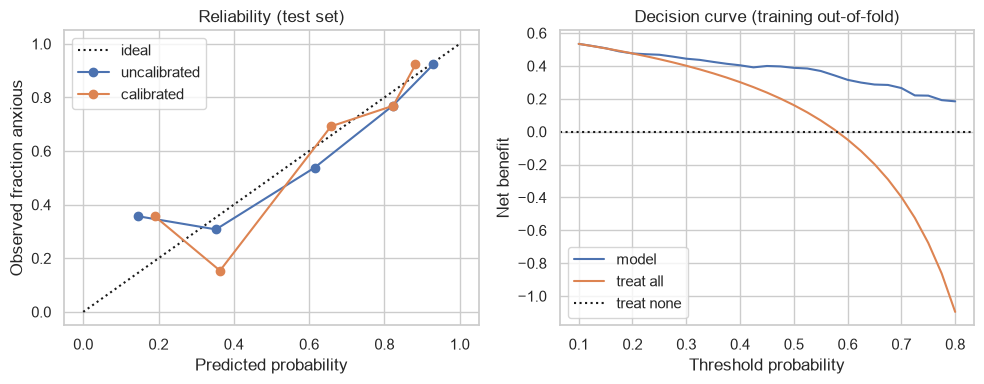

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot([0, 1], [0, 1], "k:", label="ideal")
for label, p_ in [("uncalibrated", p_test), ("calibrated", p_cal)]:
    fr, mp = calibration_curve(y_test, p_, n_bins=5, strategy="quantile"); ax[0].plot(mp, fr, "o-", label=label)
ax[0].set(xlabel="Predicted probability", ylabel="Observed fraction anxious", title="Reliability (test set)"); ax[0].legend()

thresholds, n_ = np.linspace(0.1, 0.8, 29), len(y_train)
net_benefit = [((p_train_oof >= t) & (y_train == 1)).sum() / n_ - ((p_train_oof >= t) & (y_train == 0)).sum() / n_ * t / (1 - t) for t in thresholds]
treat_all = [y_train.mean() - (1 - y_train.mean()) * t / (1 - t) for t in thresholds]
ax[1].plot(thresholds, net_benefit, label="model"); ax[1].plot(thresholds, treat_all, label="treat all"); ax[1].axhline(0, color="k", ls=":", label="treat none")
ax[1].set(xlabel="Threshold probability", ylabel="Net benefit", title="Decision curve (training out-of-fold)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 16. Which questions drive the final model on the test set?
Permutation importance: shuffle one question and measure the drop in test AUC. This shows what the model relies on, not what causes anxiety.

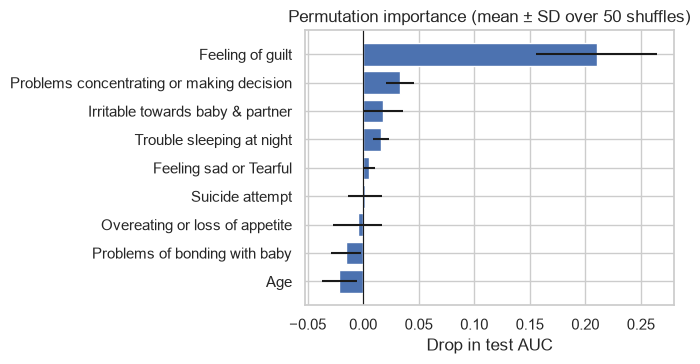

,AUC drop,SD
Feeling of guilt,0.2103,0.0544
Problems concentrating or making decision,0.0334,0.0125
Irritable towards baby & partner,0.0179,0.0180
Trouble sleeping at night,0.0160,0.0072
Feeling sad or Tearful,0.0055,0.0056
Suicide attempt,0.0013,0.0152
Overeating or loss of appetite,-0.0050,0.0222
Problems of bonding with baby,-0.0155,0.0136
Age,-0.0213,0.0158


In [22]:
pi = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=50, random_state=SEED)
importance = pd.DataFrame({"AUC drop": pi.importances_mean, "SD": pi.importances_std}, index=X_test.columns).sort_values("AUC drop", ascending=False)
importance.to_csv(RESULTS / "permutation_importance.csv")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(importance.index[::-1], importance["AUC drop"][::-1], xerr=importance["SD"][::-1]); ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Drop in test AUC", title="Permutation importance (mean ± SD over 50 shuffles)"); plt.tight_layout(); plt.show()
importance.round(4)

## 17. Leakage check: why splits are grouped by answer pattern
Same models on the raw 1,503 rows, with an ordinary split and with the grouped split.

In [23]:
def cv_auc(model, X_, y_, g_, grouped, repeats=3):
    scores = []
    for r in range(repeats):
        sp = StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r) if grouped else StratifiedKFold(5, shuffle=True, random_state=SEED + r)
        for tr, te in (sp.split(X_, y_, g_) if grouped else sp.split(X_, y_)):
            m = clone(model).fit(X_.iloc[tr], y_[tr]); scores.append(roc_auc_score(y_[te], m.predict_proba(X_.iloc[te])[:, 1]))
    return np.mean(scores)

leak_models = {"Logistic regression": MODELS["Logistic regression"](), "Random forest (depth 4)": MODELS["Random forest"](),
               "Random forest (unlimited depth)": pipe(RandomForestClassifier(n_estimators=300, random_state=SEED)),
               "Gradient boosting": MODELS["Gradient boosting"]()}
leak = pd.DataFrame({n: {"Ordinary split": cv_auc(m, X_raw, y_raw, pattern_id, False), "Grouped split": cv_auc(m, X_raw, y_raw, pattern_id, True)}
                     for n, m in leak_models.items()}).T
leak["Inflation"] = leak["Ordinary split"] - leak["Grouped split"]
leak.to_csv(RESULTS / "leakage_check.csv"); leak.round(3)

,Ordinary split,Grouped split,Inflation
Logistic regression,0.900,0.862,0.038
Random forest (depth 4),0.953,0.911,0.042
Random forest (unlimited depth),0.999,0.923,0.076
Gradient boosting,0.961,0.898,0.063


## 18. Summary

In [24]:
print(f"Selected model          : {selected}")
print(f"Train AUC / CV validation AUC / TEST AUC : {train_scores['AUC']:.3f} / {validation_auc:.3f} / {test_scores['AUC']:.3f}  (test 95% CI {ci[0,0]:.3f}-{ci[0,1]:.3f}; dummy {dummy_scores['AUC']:.3f})")
print(f"Test sensitivity / specificity (threshold 0.5) : {test_scores['Sensitivity']:.2f} / {test_scores['Specificity']:.2f}  | test set: {len(y_test)} responses, {int(y_test.sum())} anxious")
print(f"Ensembles vs best member (CV AUC): voting {cv_table.loc['Soft-voting ensemble','Validation AUC']:.3f}, stacking {cv_table.loc['Stacking ensemble','Validation AUC']:.3f}, {best_member} {cv_table.loc[best_member,'Validation AUC']:.3f}")
print(f"Explanation stability   : median Kendall tau {np.median(taus):.2f}, top-3 overlap {np.median(jaccard):.2f}")
print(f"Questions needed (within 1 SE of all {X_train.shape[1]}) : {smallest}")
print(f"Leakage inflation (mean AUC, ordinary minus grouped split) : {leak['Inflation'].mean():+.3f}")

Selected model          : Random forest
Train AUC / CV validation AUC / TEST AUC : 0.997 / 0.853 / 0.768  (test 95% CI 0.645-0.874; dummy 0.500)
Test sensitivity / specificity (threshold 0.5) : 0.76 / 0.68  | test set: 66 responses, 38 anxious
Ensembles vs best member (CV AUC): voting 0.830, stacking 0.832, Random forest 0.842
Explanation stability   : median Kendall tau 0.67, top-3 overlap 0.50
Questions needed (within 1 SE of all 9) : 7
Leakage inflation (mean AUC, ordinary minus grouped split) : +0.055
